# Day 4: Baseline without training the transformer

The transformer stays frozen: it only turns tweets into CLS embeddings (day 2). A logistic regression learns to read sentiment from these vectors. Day 2 showed that sentiment is not the main thing in them; this baseline measures how much of it a classifier can still recover, and gives day 5 a number to beat.

In [1]:
import json
import time

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    f1_score,
)
from sklearn.model_selection import train_test_split

from itg_transformers.config import (
    EMBEDDINGS_DIR,
    LABELS,
    MODEL_NAME,
    RESULTS_DIR,
    SPLITS,
)
from itg_transformers.data import load_split
from itg_transformers.embeddings import (
    cached_embeddings,
    get_embeddings,
    load_model,
)
from itg_transformers.metrics import classification_scores
from itg_transformers.tokenization import load_tokenizer, tokenize_texts

## 1. Tokenization

`load_tokenizer` and `tokenize_texts` were written on day 1. `tokenize_texts` calls the tokenizer with `padding=True`, `truncation=True`, `max_length` and `return_tensors="pt"`, as the task asks; it also drops `token_type_ids`, which DistilBERT ignores, and uses `max_length=64` (covers 99.99% of tweets, see `00_eda.ipynb`).

In [2]:
tokenizer = load_tokenizer()
print("Tokenizer:", MODEL_NAME)

examples = [
    "I love this phone, best purchase ever!",
    "Worst customer service I have ever seen.",
    "The meeting is moved to Monday.",
]
batch = tokenize_texts(examples, tokenizer)
print(f"Keys: {list(batch.keys())}")
print(f"Shape: {batch['input_ids'].shape}")
for index in range(len(examples)):
    print(batch.tokens(index))

Tokenizer: distilbert-base-uncased
Keys: ['input_ids', 'attention_mask']
Shape: torch.Size([3, 11])
['[CLS]', 'i', 'love', 'this', 'phone', ',', 'best', 'purchase', 'ever', '!', '[SEP]']
['[CLS]', 'worst', 'customer', 'service', 'i', 'have', 'ever', 'seen', '.', '[SEP]', '[PAD]']
['[CLS]', 'the', 'meeting', 'is', 'moved', 'to', 'monday', '.', '[SEP]', '[PAD]', '[PAD]']


## 2. CLS embeddings

`load_model` (day 2) loads the model through `AutoModel` and puts it in eval mode. `get_embeddings` (day 2) does exactly what the task describes for `get_cls_embeddings`: batches, `tokenize_texts`, `torch.no_grad()`, `last_hidden_state[:, 0, :]`, `.cpu().numpy()` and `np.vstack`. It takes the tokenizer and the model as arguments; `get_cls_embeddings` binds them to keep the signature from the task.

In [3]:
model = load_model()
print("Eval mode:", not model.training)


def get_cls_embeddings(texts, batch_size=32):
    return get_embeddings(texts, tokenizer, model, batch_size=batch_size)


embeddings = get_cls_embeddings(examples)
print(f"Embeddings shape: {embeddings.shape}")
assert embeddings.shape == (len(examples), model.config.hidden_size)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Eval mode: True
Embeddings shape: (3, 768)


## 3. Embeddings of the whole dataset

The dataset is `tweet_eval` sentiment, already split into train, validation and test (cleaned by `clean_text`, see `00_eda.ipynb`). Every split is a DataFrame with `text` and `label`.

In [4]:
splits = {name: load_split(name) for name in SPLITS}
texts = {name: frame["text"].tolist() for name, frame in splits.items()}
labels = {name: frame["label"].to_numpy() for name, frame in splits.items()}

for name in SPLITS:
    counts = splits[name]["label"].value_counts().sort_index().to_dict()
    print(f"{name:10} {len(texts[name]):6} texts, per label {counts}")
print("Classes:", LABELS)

train       45615 texts, per label {0: 7093, 1: 20673, 2: 17849}
validation   2000 texts, per label {0: 312, 1: 869, 2: 819}
test        12284 texts, per label {0: 3972, 1: 5937, 2: 2375}
Classes: {0: 'negative', 1: 'neutral', 2: 'positive'}


About 60,000 tweets take a minute or two on the GPU. `cached_embeddings` saves every split to `data/embeddings/` the first time and loads it afterwards, so day 6 and reruns of this notebook skip the computation. The file name includes the model, so another model never picks up these vectors.

In [5]:
model_tag = MODEL_NAME.replace("/", "__")
embeddings = {}
for name in SPLITS:
    path = EMBEDDINGS_DIR / f"{model_tag}_cls_{name}.npy"
    start = time.perf_counter()
    embeddings[name] = cached_embeddings(texts[name], path, tokenizer, model)
    seconds = time.perf_counter() - start
    print(f"{name:10} {embeddings[name].shape}  {seconds:5.1f} s  {path.name}")

train      (45615, 768)    0.1 s  distilbert-base-uncased_cls_train.npy
validation (2000, 768)    0.0 s  distilbert-base-uncased_cls_validation.npy
test       (12284, 768)    0.0 s  distilbert-base-uncased_cls_test.npy


## 4. Logistic regression on the embeddings

As the task asks: an 80/20 split with `stratify=y` and `random_state=42`. It is done inside the official train split, so both parts come from the same distribution; the official test set follows in section 5.

In [6]:
X = embeddings["train"]
y = labels["train"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print(f"Train: {X_train.shape}, test: {X_test.shape}")

Train: (36492, 768), test: (9123, 768)


`n_jobs=-1` from the task is left out: since scikit-learn 1.8 it has no effect on `LogisticRegression` and only raises a FutureWarning.

In [7]:
classifier = LogisticRegression(max_iter=1000)

start = time.perf_counter()
classifier.fit(X_train, y_train)
print(
    f"Fitted in {time.perf_counter() - start:.1f} s, "
    f"{classifier.n_iter_[0]} iterations"
)

y_pred = classifier.predict(X_test)

Fitted in 5.7 s, 574 iterations


In [8]:
print(
    classification_report(
        y_test, y_pred, target_names=list(LABELS.values()), digits=3
    )
)

f1 = f1_score(y_test, y_pred, average="macro")
print(f"Macro F1: {f1:.3f}")

              precision    recall  f1-score   support

    negative      0.592     0.486     0.534      1419
     neutral      0.653     0.707     0.679      4134
    positive      0.701     0.684     0.692      3570

    accuracy                          0.663      9123
   macro avg      0.649     0.625     0.635      9123
weighted avg      0.662     0.663     0.662      9123

Macro F1: 0.635


For scale, always predicting the most frequent class on the same 20%:

In [9]:
majority = int(pd.Series(y_train).mode().iloc[0])
trivial = classification_scores(y_test.tolist(), [majority] * len(y_test))
print(
    f"Always '{LABELS[majority]}': accuracy {trivial['accuracy']:.3f}, "
    f"macro F1 {trivial['macro_f1']:.3f}"
)

Always 'neutral': accuracy 0.453, macro F1 0.208


The frozen transformer plus a linear classifier reaches a macro F1 of about 0.64, three times the trivial 0.21. So sentiment *is* in the CLS vectors, even though day 2 showed it is not their main content: the regression found the directions that carry it.

By class, negative is the weakest (F1 0.53, recall 0.49): it is the rarest class in train (16%), and the regression misses half of the negative tweets. Neutral and positive are close to 0.68-0.69.

## 5. Evaluation on the official splits

The 80/20 split above tests on tweets from the same distribution as training. Days 5 and 6 will be compared on the official validation and test splits, and test differs from train (other topics, twice as many negative tweets, see `00_eda.ipynb`). The same regression, fitted on the whole official train split:

In [10]:
official = LogisticRegression(max_iter=1000)
official.fit(embeddings["train"], labels["train"])

predictions = {name: official.predict(embeddings[name]) for name in SPLITS}
official_scores = pd.DataFrame(
    {
        name: classification_scores(
            labels[name].tolist(), predictions[name].tolist()
        )
        for name in SPLITS
    }
).T
official_scores.round(3)

,accuracy,macro_f1
train,0.685,0.662
validation,0.667,0.632
test,0.660,0.650


In [11]:
print(
    classification_report(
        labels["test"],
        predictions["test"],
        target_names=list(LABELS.values()),
        digits=3,
    )
)

              precision    recall  f1-score   support

    negative      0.686     0.646     0.665      3972
     neutral      0.663     0.690     0.676      5937
    positive      0.609     0.607     0.608      2375

    accuracy                          0.660     12284
   macro avg      0.653     0.648     0.650     12284
weighted avg      0.660     0.660     0.660     12284



Rows of the confusion matrix are the true classes, normalized so that every row sums to 1: the diagonal is the recall of each class.

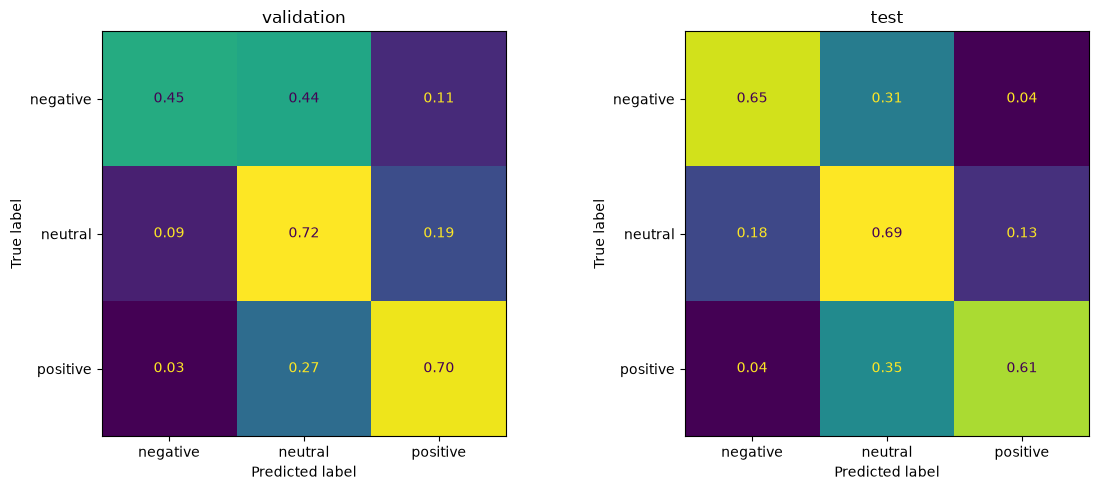

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["validation", "test"], strict=True):
    ConfusionMatrixDisplay.from_predictions(
        labels[name],
        predictions[name],
        display_labels=list(LABELS.values()),
        normalize="true",
        values_format=".2f",
        colorbar=False,
        ax=ax,
    )
    ax.set_title(name)
plt.tight_layout()
plt.show()

The official numbers agree with the 80/20 split: macro F1 0.63 on validation and 0.65 on test, against 0.22 for the trivial baseline on test. The EDA expected test to be noticeably harder; for this baseline it is not:

- **Negative is much better on test** (recall 0.65 against 0.45 on validation). Test negatives are mostly angry political tweets with explicit wording, easier to spot than the mild complaints of train. Precision of negative also profits from test having twice as many negative tweets: a predicted negative is more often right when negatives are common.
- **Positive is worse on test** (recall 0.61 against 0.70): many test positives read like news, and 35% of them are taken for neutral.
- **Almost all errors involve neutral.** Negative and positive are confused with each other in only 3-11% of cases, as the EDA predicted: neutral is the fuzzy class.

Train still scores higher than validation and test (0.66), the regression overfits a little, but only a little: it has 2,307 weights for 45,615 tweets.

## 6. Saving the results

`results/baseline_results.txt` is the human-readable report the task asks for, with the macro F1. `results/baseline_results.json` holds the same numbers for day 6, which compares them with the fine-tuned model. Unlike `data/` and `figures/`, `results/` is meant to be committed.

In [13]:
target_names = list(LABELS.values())
test_trivial = classification_scores(
    labels["test"].tolist(), [majority] * len(labels["test"])
)
report = "\n".join(
    [
        f"Baseline: frozen {MODEL_NAME} CLS embeddings",
        "Classifier: LogisticRegression(max_iter=1000)",
        "",
        "80/20 stratified split of the train split (random_state=42)",
        f"Macro F1: {f1:.4f}",
        "",
        classification_report(
            y_test, y_pred, target_names=target_names, digits=3
        ),
        "Official splits, regression fitted on the whole train split",
        official_scores.round(4).to_string(),
        "",
        "Test split:",
        classification_report(
            labels["test"],
            predictions["test"],
            target_names=target_names,
            digits=3,
        ),
        f"Trivial baseline on test (always '{LABELS[majority]}'): "
        f"macro F1 {test_trivial['macro_f1']:.4f}",
    ]
)

RESULTS_DIR.mkdir(exist_ok=True)
(RESULTS_DIR / "baseline_results.txt").write_text(report + "\n")
print(report)

Baseline: frozen distilbert-base-uncased CLS embeddings
Classifier: LogisticRegression(max_iter=1000)

80/20 stratified split of the train split (random_state=42)
Macro F1: 0.6349

              precision    recall  f1-score   support

    negative      0.592     0.486     0.534      1419
     neutral      0.653     0.707     0.679      4134
    positive      0.701     0.684     0.692      3570

    accuracy                          0.663      9123
   macro avg      0.649     0.625     0.635      9123
weighted avg      0.662     0.663     0.662      9123

Official splits, regression fitted on the whole train split
            accuracy  macro_f1
train         0.6853    0.6623
validation    0.6670    0.6319
test          0.6596    0.6499

Test split:
              precision    recall  f1-score   support

    negative      0.686     0.646     0.665      3972
     neutral      0.663     0.690     0.676      5937
    positive      0.609     0.607     0.608      2375

    accuracy           

In [14]:
results = {
    "model": MODEL_NAME,
    "features": "cls",
    "classifier": "LogisticRegression(max_iter=1000)",
    "split_80_20": {"macro_f1": f1},
    "official": official_scores.to_dict(orient="index"),
}
(RESULTS_DIR / "baseline_results.json").write_text(
    json.dumps(results, indent=2)
)
for path in sorted(RESULTS_DIR.iterdir()):
    print(path.relative_to(RESULTS_DIR.parent))

results/baseline_results.json
results/baseline_results.txt
